# Tarea #5. Ejemplo de perceptrón en Python

**Materia:** Inteligencia Artificial     
**Profesor:** José Mario Ríos Félix

**Alumna:** Crespo Hernández Kitzia Marisol     
**No. de Control:** C23171148

Se entrena un perceptrón con scikit-learn para clasificar dos grupos de puntos, se explican las funciones de activación y se incluye como complemento el ejemplo de neurona lineal visto en clase.

## 1. Perceptrón

El perceptrón es un modelo sencillo de neurona artificial que se utiliza para clasificar datos. Recibe valores de entrada, los multiplica por sus respectivos pesos, suma un sesgo (*bias*) y aplica una función escalón para determinar a qué clase pertenece cada dato.

En este ejercicio se utiliza **Perceptron** de *scikit-learn* para entrenar un modelo que aprenda a separar dos grupos de puntos mediante una recta.

**Fuente de referencia:** https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Perceptron.html

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.linear_model import Perceptron

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Se generan dos grupos de puntos que se pueden separar trazando una recta entre ellos
# Cada punto tiene dos características y pertenece a la clase 0 o a la clase 1
X, Y = make_blobs(n_samples=100, centers=2, n_features=2, cluster_std=1.0, random_state=42)

print(f"Puntos generados: {len(X)}")
print(f"Características por punto: {X.shape[1]}")
print(f"Puntos de la clase 0: {np.sum(Y == 0)}    Puntos de la clase 1: {np.sum(Y == 1)}")

Puntos generados: 100
Características por punto: 2
Puntos de la clase 0: 50    Puntos de la clase 1: 50


In [16]:
# El perceptrón recorre los datos varias veces y corrige los pesos cada vez que se equivoca
clasificador = Perceptron(tol=1e-3, random_state=0)
clasificador.fit(X, Y)

# coef_ guarda los pesos de cada característica e intercept_ guarda el sesgo
w1, w2 = clasificador.coef_[0]
b = clasificador.intercept_[0]

print("--- PARÁMETROS APRENDIDOS ---")
print(f"Peso de la característica 1 (w1): {w1:.4f}")
print(f"Peso de la característica 2 (w2): {w2:.4f}")
print(f"Sesgo (bias): {b:.4f}")

print(f"\nÉpocas que necesitó: {clasificador.n_iter_}")
print(f"Datos procesados durante el entrenamiento: {clasificador.n_iter_ * len(X)}")
print(f"Exactitud sobre los datos de entrenamiento: {clasificador.score(X, Y):.2%}")

--- PARÁMETROS APRENDIDOS ---
Peso de la característica 1 (w1): 11.2337
Peso de la característica 2 (w2): -3.4070
Sesgo (bias): 1.0000

Épocas que necesitó: 7
Datos procesados durante el entrenamiento: 700
Exactitud sobre los datos de entrenamiento: 100.00%


In [17]:
# Se comprueba cómo el perceptrón obtiene sus predicciones
# Primero se multiplica cada entrada por su peso y se suma el sesgo

suma_ponderada = X @ clasificador.coef_[0] + b

# Después se aplica la función escalón, que devuelve 1 si la suma es mayor o igual a cero y 0 si no
salida_escalon = (suma_ponderada >= 0).astype(int)

print("--- COMPROBACIÓN DE LA FUNCIÓN ESCALÓN ---")
print(f"Suma ponderada de los primeros cinco puntos: {np.round(suma_ponderada[:5], 2)}")
print(f"Salida del escalón para esos puntos:         {salida_escalon[:5]}")
print(f"Clase real de esos puntos:                   {Y[:5]}")

print(f"\nLa función escalón coincide con las predicciones del modelo: {np.array_equal(salida_escalon, clasificador.predict(X))}")

--- COMPROBACIÓN DE LA FUNCIÓN ESCALÓN ---
Suma ponderada de los primeros cinco puntos: [-62.65  54.98 -64.39  49.17  44.5 ]
Salida del escalón para esos puntos:         [0 1 0 1 1]
Clase real de esos puntos:                   [0 1 0 1 1]

La función escalón coincide con las predicciones del modelo: True


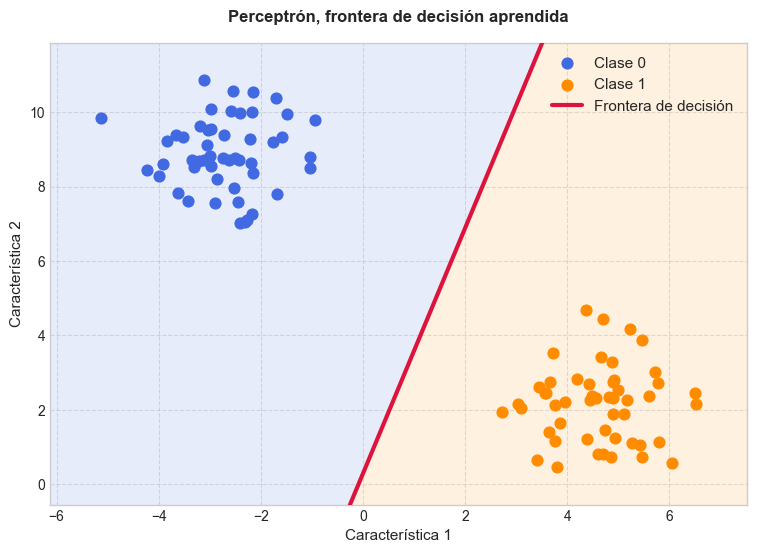

In [18]:
plt.figure(figsize=(9, 6))

# Se pinta el fondo de acuerdo con la clase que el modelo predice en cada zona del plano

paso = 0.05
rejilla_x1, rejilla_x2 = np.meshgrid(
    np.arange(X[:, 0].min() - 1, X[:, 0].max() + 1, paso),
    np.arange(X[:, 1].min() - 1, X[:, 1].max() + 1, paso),
)
zonas = clasificador.predict(np.c_[rejilla_x1.ravel(), rejilla_x2.ravel()]).reshape(rejilla_x1.shape)
plt.contourf(rejilla_x1, rejilla_x2, zonas, levels=[-0.5, 0.5, 1.5], colors=['royalblue', 'darkorange'], alpha=0.12)

# Los puntos reales de cada clase
plt.scatter(X[Y == 0][:, 0], X[Y == 0][:, 1], color='royalblue', s=60, label='Clase 0', zorder=5)
plt.scatter(X[Y == 1][:, 0], X[Y == 1][:, 1], color='darkorange', s=60, label='Clase 1', zorder=5)

# La frontera de decisión es la recta donde la suma ponderada vale cero
# De w1 * x1 + w2 * x2 + b = 0 se despeja x2
x1_recta = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 100)
x2_recta = -(w1 * x1_recta + b) / w2
plt.plot(x1_recta, x2_recta, color='crimson', linewidth=3, label='Frontera de decisión', zorder=4)

plt.title('Perceptrón, frontera de decisión aprendida', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Característica 1', fontsize=11)
plt.ylabel('Característica 2', fontsize=11)
plt.xlim(X[:, 0].min() - 1, X[:, 0].max() + 1)
plt.ylim(X[:, 1].min() - 1, X[:, 1].max() + 1)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

### Explicación de los resultados

La recta aprendida por el perceptrón es **11.2337 * x1 - 3.4070 * x2 + 1 = 0**, donde se utilizan dos pesos y un sesgo para separar los grupos de puntos. Asimismo, se puede destacar que el perceptrón necesitó 7 épocas y clasificó correctamente el 100 % de los datos de entrenamiento, ya que ambos grupos pueden separarse mediante una recta.

La función escalón produjo las mismas predicciones que el modelo. En la gráfica, los colores del fondo muestran qué clase predice el perceptrón en cada zona.

## 2. Función de activación

La función de activación es la transformación que se aplica al resultado de la suma ponderada de una neurona, después de multiplicar las entradas por sus pesos y sumar el sesgo. Esta transformación determina la salida de la neurona, que puede utilizarse como resultado del modelo o enviarse a la siguiente capa.

En el ejemplo anterior, el perceptrón utiliza la función escalón, que devuelve 0 o 1 para determinar a qué clase pertenece cada dato.

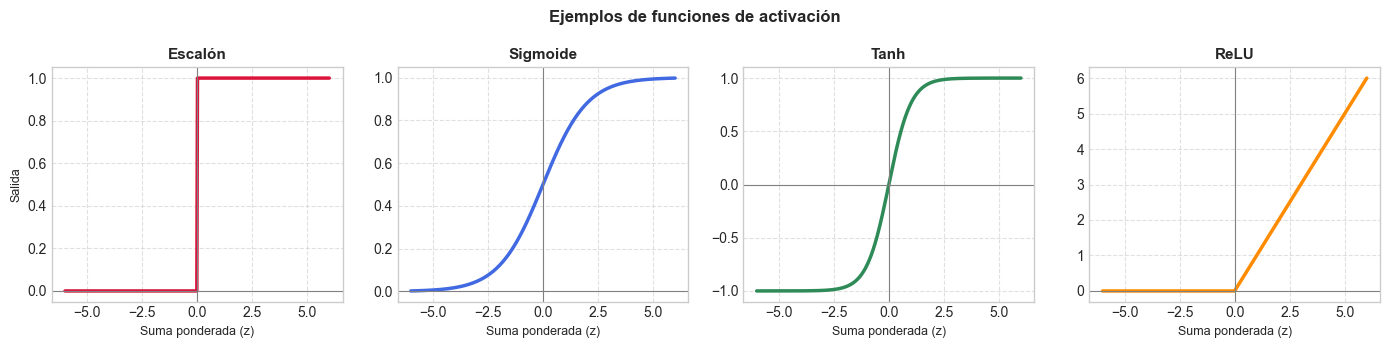

In [19]:
# Se evalúan cuatro funciones de activación sobre el mismo rango de valores
z = np.linspace(-6, 6, 400)

escalon = (z >= 0).astype(float)
sigmoide = 1 / (1 + np.exp(-z))
tangente_hiperbolica = np.tanh(z)
relu = np.maximum(0, z)

activaciones = [
    ('Escalón', escalon, 'crimson'),
    ('Sigmoide', sigmoide, 'royalblue'),
    ('Tanh', tangente_hiperbolica, 'seagreen'),
    ('ReLU', relu, 'darkorange'),
]

figura, ejes = plt.subplots(1, 4, figsize=(14, 3.5))

for eje, (nombre, valores, color) in zip(ejes, activaciones):
    eje.plot(z, valores, color=color, linewidth=2.5)
    eje.axhline(0, color='gray', linewidth=0.8)
    eje.axvline(0, color='gray', linewidth=0.8)
    eje.set_title(nombre, fontsize=11, fontweight='bold')
    eje.set_xlabel('Suma ponderada (z)', fontsize=9)
    eje.grid(True, linestyle='--', alpha=0.6)

ejes[0].set_ylabel('Salida', fontsize=9)
figura.suptitle('Ejemplos de funciones de activación', fontsize=12, fontweight='bold')
figura.tight_layout()

plt.show()

### Importancia de las funciones de activación

Cada función transforma los valores de manera diferente. El escalón devuelve 0 o 1, la sigmoide valores entre 0 y 1, la tangente hiperbólica entre -1 y 1, mientras que ReLU convierte los valores negativos en cero y conserva los positivos. Por otra parte, las funciones de activación no lineales permiten que las redes neuronales aprendan relaciones más complejas, y sin ellas, aunque se agreguen más capas, la red seguiría limitada a relaciones lineales.

Esto se observó en clase con TensorFlow Playground. Al trabajar con datos en forma de espiral, una red con activación lineal obtuvo aproximadamente un 47% de precisión. Al utilizar funciones como ReLU, agregar neuronas y capas, y ajustar las características de entrada, la red logró aprender mejor cómo separar los dos grupos.

## 3. Ejemplo de neurona lineal visto en clase

Este ejemplo se trabajó en clase y utiliza `SGDRegressor` de `scikit-learn` para convertir temperaturas de grados Celsius a Fahrenheit mediante una neurona lineal entrenada con descenso de gradiente estocástico.

El modelo aprende a predecir valores continuos a partir de los datos de entrenamiento, utilizando pesos y un sesgo para obtener los resultados.

In [20]:
import numpy as np
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import StandardScaler

# 1. Datos de entrenamiento (Celsius y sus equivalentes exactos en Fahrenheit)
X_celsius = np.array([-40, -20, 0, 10, 20, 30, 40, 100]).reshape(-1, 1)
y_fahrenheit = X_celsius.ravel() * 1.8 + 32

# 2. Escalado de datos (fundamental para que el descenso de gradiente converja rápido y bien)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_celsius)

# 3. Entrenar la neurona lineal (Regresión con Descenso de Gradiente Estocástico)
regressor = SGDRegressor(max_iter=1000, tol=1e-3, learning_rate='invscaling', eta0=0.01, random_state=42)
regressor.fit(X_scaled, y_fahrenheit)

# 4. Probar predicciones de valores continuos
test_celsius = np.array([15, 25, 37]).reshape(-1, 1)
test_scaled = scaler.transform(test_celsius)
predictions = regressor.predict(test_scaled)

print("\n--- RESULTADOS REGRESIÓN (NEURONA LINEAL) ---")
for c, f_pred in zip(test_celsius.ravel(), predictions):
    f_real = c * 1.8 + 32
    print(f"{c}°C -> Predicho por la neurona: {f_pred:.2f}°F | Real: {f_real:.2f}°F")


--- RESULTADOS REGRESIÓN (NEURONA LINEAL) ---
15°C -> Predicho por la neurona: 58.82°F | Real: 59.00°F
25°C -> Predicho por la neurona: 76.76°F | Real: 77.00°F
37°C -> Predicho por la neurona: 98.30°F | Real: 98.60°F


In [21]:
# ==========================================
# 4. Obtener W y Bias del modelo (Escalados)
# ==========================================
w_scaled = regressor.coef_[0]
bias_scaled = regressor.intercept_[0]

print("--- PARÁMETROS EN EL ESPACIO ESCALADO ---")
print(f"Peso (W): {w_scaled:.4f}")
print(f"Sesgo (Bias): {bias_scaled:.4f}")

# ==========================================
# 5. Reconstruir W y Bias a la escala original (°C)
# ==========================================
# Fórmula de transformación inversa del StandardScaler:
# X_scaled = (X - media) / desviacion_estandar
# Por tanto: W_original = W_scaled / desviacion_estandar
# Bias_original = Bias_scaled - (W_scaled * media / desviacion_estandar)

media = scaler.mean_[0]
desviacion = scaler.scale_[0]

w_original = w_scaled / desviacion
bias_original = bias_scaled - (w_scaled * media / desviacion)

print("\n--- PARÁMETROS EN LA ESCALA ORIGINAL (°C) ---")
print(f"Peso original (W): {w_original:.4f}  (Idealmente cercano a 1.8)")
print(f"Sesgo original (Bias): {bias_original:.4f} (Idealmente cercano a 32.0)")

# Comprobación de la ecuación de la recta aprendida: F = (W_original * C) + Bias_original
print(f"\nEcuación aprendida: F = {w_original:.2f} * C + {bias_original:.2f}")

--- PARÁMETROS EN EL ESPACIO ESCALADO ---
Peso (W): 71.0714
Sesgo (Bias): 63.3055

--- PARÁMETROS EN LA ESCALA ORIGINAL (°C) ---
Peso original (W): 1.7944  (Idealmente cercano a 1.8)
Sesgo original (Bias): 31.9036 (Idealmente cercano a 32.0)

Ecuación aprendida: F = 1.79 * C + 31.90


### Resultados obtenidos

El modelo aprendió la ecuación **F = 1.79 · C + 31.90**, muy cercana a la fórmula real de conversión **F = 1.8 · C + 32**, por lo que logró realizar predicciones bastante aproximadas.